# Cyclone SAE: GraphCast → corpus → one feature

Run the cells in order for **1 September 2019, 18 UTC**. GraphCast takes ERA5 at **12 and 18 UTC**, predicts **2 September, 00 UTC**, and supplies 16 post-residual processor states associated with the **18 UTC initialization**. The physical target and feature map are at 18 UTC.

### 1. Paths and selection
Choose `LAYER` from **0–15** and seed `50108`; seed `50109` is also available at Layer 8. Set `RUN_GRAPHCAST=False` to use the saved corpus. After the corpus exists, changing layers only requires rerunning this configuration cell and the SAE steps below. Changing the GraphCast path or GPU in an active kernel requires a kernel restart.

In [1]:
from pathlib import Path
import os
os.environ["OPENBLAS_NUM_THREADS"] = "4"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
%matplotlib inline
import numpy as np
from src.sae import load_corpus, load_sae, encode, rank_features, select_feature
from src.plot import plot_feature

ROOT = Path.cwd()
GRAPHCAST_ROOT = (ROOT.parent / "GenCast" / "graphcast").resolve()
GRAPHCAST_CHECKPOINT = ROOT / "checkpoints" / "graphcast.npz"
ERA5_FILE = ROOT / "data" / "era5.nc"
STATS_DIR = ROOT / "data" / "stats"
RUN_GRAPHCAST = True
LAYER = 0
SEED = 50108

### 2. Run one GraphCast step
One GPU forward pass computes all 16 layers; this cell saves them as `data/layer00.npy` … `layer15.npy`, plus `data/prediction.nc`. The first call also compiles the model. Set `RUN_GRAPHCAST=False` above to skip this step. The ERA5 file contains actual fields for three times; the final time supplies the target template and forcing, while predicted weather is computed by GraphCast.

In [2]:
if RUN_GRAPHCAST:
    import xarray as xr
    from src.graphcast_run import run_graphcast
    with xr.open_dataset(ERA5_FILE) as ds, np.load(ROOT / "data" / "physical.npz") as ref:
        center = np.asarray(ds.datetime).reshape(-1)[1]
        assert center == np.datetime64(str(ref["timestamp_utc"]).removesuffix("Z")), "ERA5 and physical reference times differ"
    result = run_graphcast(GRAPHCAST_ROOT, GRAPHCAST_CHECKPOINT, ERA5_FILE,
                           STATS_DIR, layers=range(16), output_dir=ROOT / "data")
    print("Corpus initialization:", result["center_time"])
    print("Forecast valid time:", result["valid_time"])
    print("Saved", len(result["corpus_files"]), "layers and", result["prediction_file"])
else:
    print("Using saved corpus; no GraphCast execution.")

### 3. Load the saved corpus and physical reference
The raw corpus is BF16, one full 40,962-node mesh. The loader decodes it to float32. Pressure anomalies and the simultaneous cyclone target are the accepted ADEMPTOR physical reference for this time.

In [3]:
x = load_corpus(ROOT / "data" / f"layer{LAYER:02d}.npy")
with np.load(ROOT / "data" / "physical.npz") as f:
    physical = dict(f)
with np.load(ROOT / "data" / "coastlines.npz") as f:
    coastlines = dict(f)
assert x.shape == (40962, 512) and len(physical["target"]) == len(x)
print(str(physical["timestamp_utc"]), x.shape)
print("Cyclone target:", int(physical["target"].sum()), "mesh nodes")

2019-09-01T18:00:00Z (40962, 512)
Cyclone target: 25 mesh nodes


### 4. Encode the corpus
Each row is centered and divided by its L2 norm with epsilon `1e-6`; the SAE then applies its learned pre-bias, encoder, ReLU and TopK=32. The output stores only 32 activations per node. CPU NumPy is sufficient for this example.

In [4]:
sae = load_sae(ROOT / "checkpoints" / f"layer{LAYER:02d}_seed{SEED}.npz", layer=LAYER, seed=SEED)
feature_ids, values = encode(x, sae)
print("Sparse output:", values.shape)

Sparse output: (40962, 32)


### 5. Rank features at this time
F1 compares positive activation support with the **global simultaneous cyclone target**. Map bounds only control the view; they do not change the ranking. This is single-time ranking, unlike the paper panel's full-evaluation-period selection.

In [5]:
ranking = rank_features(feature_ids, values, physical["target"])
print("rank  feature       F1  active  overlap")
for row in ranking[:4]:
    print(f"{row['rank']:4d}  {row['feature_id']:7d}  {row['f1']:7.4f}  {row['active_count']:6d}  {row['overlap_count']:7d}")

rank  feature       F1  active  overlap
   1     1147   0.6087      21       14
   2      446   0.4051      54       16
   3     3775   0.3030       8        5
   4     1424   0.2472      64       11


### 6. Choose one feature and draw
Change `RANK` to **1, 2, 3 or 4**, then rerun this cell. `None` uses the paper's Dorian–Juliette region. You can also set longitude/latitude bounds, such as `(-117, -69)` and `(7, 34)`. White/black rings mark target mesh nodes; colored dots show positive feature activations.

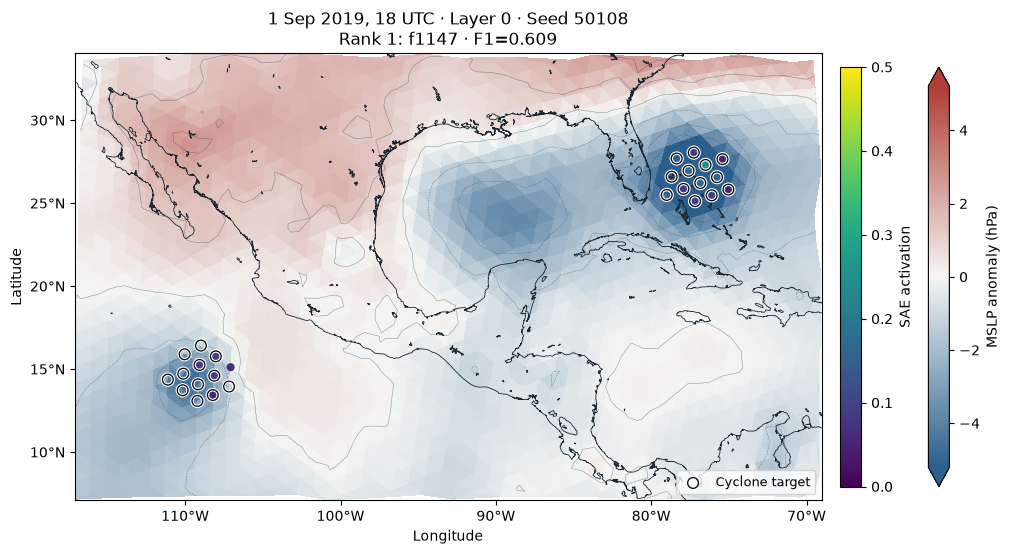

In [6]:
RANK = 1
LON_RANGE = None
LAT_RANGE = None

assert 1 <= RANK <= 4
selected = ranking[RANK - 1]
activation = select_feature(feature_ids, values, selected["feature_id"])
fig = plot_feature(activation, physical, coastlines,
    title=f"1 Sep 2019, 18 UTC · Layer {LAYER} · Seed {SEED}\nRank {RANK}: f{selected['feature_id']} · F1={selected['f1']:.3f}",
    lon_range=LON_RANGE, lat_range=LAT_RANGE)

### 7. Save this feature and figure
Rerunning this cell updates `feature.npz` and `feature.png` in the main folder.

In [7]:
np.savez_compressed(ROOT / "feature.npz", activation=activation,
    feature_id=selected["feature_id"], rank=RANK, layer=LAYER, seed=SEED,
    timestamp_utc=physical["timestamp_utc"])
fig.savefig(ROOT / "feature.png", dpi=160)
print("Saved feature.npz and feature.png")

Saved feature.npz and feature.png


The map uses **single-time global F1**, while longitude/latitude settings only change the view. All 16 corpus files are genuine outputs of the same GraphCast initialization; SAE feature IDs remain local to a layer and seed.